# Финальный экзамен. Плей-офф НХЛ 2025/2026

Решение по приложенному файлу NHL-playoffs-2026.xlsx.
В ноутбуке сохранены код, результаты и четыре графика по всем 22 пунктам:
для проверки достаточно открыть его без запуска. Для повторного расчета
положите исходную таблицу рядом и выполните ячейки сверху вниз.
Нужны pandas, numpy, openpyxl, matplotlib, seaborn и IPython.

## 1. Чтение данных

Первый столбец Excel содержит сохраненный индекс. Убираем его из признаков,
дату преобразуем в datetime. Пропуски в составах не считаем отдельными игроками.

In [1]:
from pathlib import Path
from io import BytesIO
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns
from IPython import get_ipython
from IPython.display import display, Image

pd.set_option("display.float_format", lambda value: f"{value:.3f}")
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=0.9)


def show_plot(filename):
    """Сохранить рисунок и встроить его в вывод ячейки."""
    fig = plt.gcf()
    fig.tight_layout()
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=160, bbox_inches="tight")
    if get_ipython() is not None:
        display(Image(data=buffer.getvalue()))
    else:
        Path("figures").mkdir(exist_ok=True)
        (Path("figures") / filename).write_bytes(buffer.getvalue())
    plt.close(fig)


events = pd.read_excel("NHL-playoffs-2026.xlsx", index_col=0)
events["Date"] = pd.to_datetime(events["Date"])
events = events.sort_values(["Game ID", "Play ID"])
print("Размер исходных данных:", events.shape)
display(events.iloc[:10][["Date", "Away Team", "Home Team",
                          "Remaining Time", "Play Type"]])

Размер исходных данных: (29710, 38)


,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


## 2. Сводка по каждой игре

Итоговый счет берем из последнего события игры, число овертаймов равно
максимальному номеру периода минус три. В таблице 82 строки: по одной на матч.

In [2]:
games = events.groupby("Game ID").agg(
    Date=("Date", "first"),
    **{
        "Away Team": ("Away Team", "first"),
        "Home Team": ("Home Team", "first"),
        "Away Score": ("Cumulated Away Score", "last"),
        "Home Score": ("Cumulated Home Score", "last"),
        "Overtimes": ("Period", lambda x: max(int(x.max()) - 3, 0)),
    }
)
games["Outcome"] = games["Overtimes"].map(
    lambda n: "Final" if n == 0 else "Final/OT" if n == 1 else f"Final/{n}OT"
)
games = games[["Date", "Away Team", "Home Team", "Away Score",
               "Home Score", "Outcome", "Overtimes"]]
print("Число матчей:", len(games))
display(games.tail())

Число матчей: 82


,Date,Away Team,Home Team,Away Score,Home Score,Outcome,Overtimes
Game ID,,,,,,,
2025030412,2026-06-04,Vegas Golden Knights,Carolina Hurricanes,3,4,Final/OT,1
2025030413,2026-06-06,Carolina Hurricanes,Vegas Golden Knights,4,5,Final/2OT,2
2025030414,2026-06-09,Carolina Hurricanes,Vegas Golden Knights,5,3,Final,0
2025030415,2026-06-11,Vegas Golden Knights,Carolina Hurricanes,2,4,Final,0
2025030416,2026-06-14,Carolina Hurricanes,Vegas Golden Knights,3,0,Final,0


## 3. Функция gameInfo(gameId)

Как в примере задания, сначала указаны хозяева, затем гости.

In [3]:
def gameInfo(gameId):
    g = games.loc[gameId]
    return (
        f"{g['Home Team']} - {g['Away Team']} "
        f"({g['Home Score']} - {g['Away Score']}, "
        f"{g['Outcome']}, {g['Date']:%Y-%m-%d})"
    )


print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


## 4. Общее число голов: описательная статистика

In [4]:
games["Total Score"] = games["Away Score"] + games["Home Score"]
display(games["Total Score"].describe().to_frame())

,Total Score
count,82.000
mean,5.927
std,2.260
min,1.000
25%,5.000
50%,6.000
75%,7.000
max,15.000


## 5. Гистограмма результативности

Указываем также отсутствующие значения 12, 13 и 14, чтобы сохранить
одинаковый шаг шкалы. Высота столбца равна числу матчей.

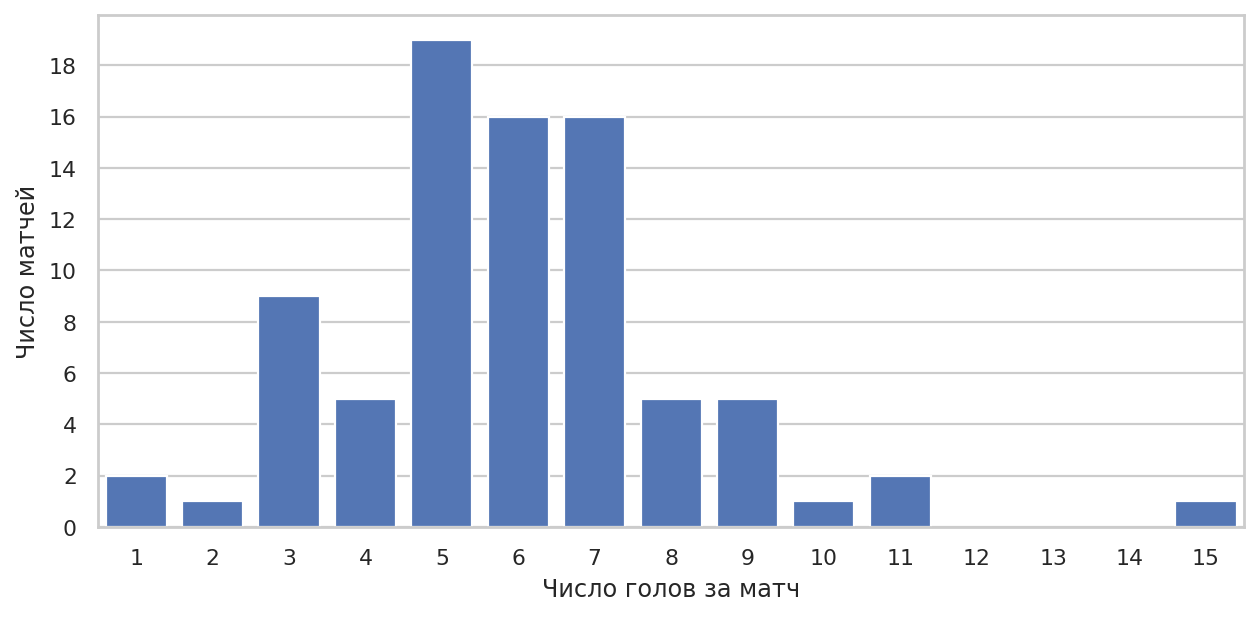

Матчей с 5–7 голами: 51 из 82 (62.2%).


In [5]:
plt.figure(figsize=(8, 4))
sns.countplot(
    data=games, x="Total Score",
    order=range(int(games["Total Score"].min()),
                int(games["Total Score"].max()) + 1),
    color="#4472c4",
)
plt.xlabel("Число голов за матч")
plt.ylabel("Число матчей")
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))
show_plot("fig5_total_goals.png")
central = games["Total Score"].between(5, 7)
print(f"Матчей с 5–7 голами: {central.sum()} из {len(games)} ({central.mean():.1%}).")

Среднее равно 5.927, медиана 6, наиболее частое значение 5 голов.
Половина матчей лежит между 5 и 7 голами по квартилям.
Есть редкий результат 15 голов, формирующий длинный правый хвост.

## 6. Самые нерезультативные и результативные матчи

In [6]:
least_ids = games.index[games["Total Score"].eq(games["Total Score"].min())]
most_ids = games.index[games["Total Score"].eq(games["Total Score"].max())]
print("Минимум голов:")
for game_id in least_ids:
    print(gameInfo(game_id))
print("\nМаксимум голов:")
for game_id in most_ids:
    print(gameInfo(game_id))

Минимум голов:
Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)

Максимум голов:
Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)


## 7. Число участвовавших игроков

Объединяем шесть полей игроков и поле вратаря для каждой стороны.
Один игрок учитывается один раз в паре «матч, команда», даже если
вратарь одновременно записан в обычном слоте и в поле вратаря.
Полученный список участников также нужен для знаменателей в пунктах 19–20.

In [7]:
appearance_parts = []
for side in ["Away", "Home"]:
    roster_columns = [
        f"{side} Team's Player on the Ice #{i}" for i in range(1, 7)
    ] + [f"{side} Team's Goalie"]
    part = events.melt(
        id_vars=["Game ID", f"{side} Team"],
        value_vars=roster_columns, value_name="Player",
    ).rename(columns={f"{side} Team": "Team"})
    appearance_parts.append(part[["Game ID", "Team", "Player"]].dropna())

appearances = pd.concat(appearance_parts).drop_duplicates()
player_counts = appearances.groupby("Game ID").size().rename("Player Count")
max_player_ids = player_counts.index[player_counts.eq(player_counts.max())]
display(pd.DataFrame({
    "Game Info": [gameInfo(i) for i in max_player_ids],
    "Player Count": player_counts.loc[max_player_ids].to_numpy(),
}, index=max_player_ids))
display(
    appearances[appearances["Game ID"].isin(max_player_ids)]
    .groupby(["Game ID", "Team"]).size().rename("Players").to_frame()
)

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Final, 2026-05-16)",40


Players
Game ID    Team                       
2025030216 Buffalo Sabres           20
           Montréal Canadiens       20

В приложенной таблице максимум составляет 40 разных игроков:
по 20 у Buffalo и Montréal в матче 2025030216.
В примере задания указано 41, но в исходном файле столько уникальных
непустых имен нет; пропуск не является еще одним игроком.

## 8. Расстояние до ближайшей точки створа

Голы входят в число точных бросков. Для координаты створа X = ±89
расстояние равно hypot(x - X, max(abs(y) - 3, 0)).
Это эквивалентно всем трем ветвям формулы задания и учитывает ширину ворот.

In [8]:
unblocked_types = ["shot-on-goal", "goal", "missed-shot"]
all_shot_types = unblocked_types + ["blocked-shot"]
shots = events[events["Play Type"].isin(unblocked_types)].copy()
is_home_shot = shots["Team Making the Play"].eq(shots["Home Team"])
home_defends_left = shots["Home Team's Defending Side"].eq("left")
shots["Goal X"] = np.where(is_home_shot.eq(home_defends_left), 89, -89)
shots["Shot Length"] = np.hypot(
    shots["X Coordinate on the Ice Rink"] - shots["Goal X"],
    (shots["Y Coordinate on the Ice Rink"].abs() - 3).clip(lower=0),
)
events["Shot Length"] = shots["Shot Length"]
print("Число незаблокированных бросков:", len(shots))
display(pd.concat([shots.head(), shots.tail()])[
    ["Game ID", "Play Type", "Shot Length"]
])

Число незаблокированных бросков: 7266


,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926
29707,2025030416,shot-on-goal,49.041


## 9. Распределения длины точных и неточных бросков

Одинаковые интервалы по 5 футов; каждая группа нормируется отдельно
(stat="density", common_norm=False). Площадь под каждой гистограммой
равна единице, поэтому разные размеры групп не искажают сравнение.

,Count,Mean,Median
Accuracy,,,
Неточный,2643,34.014,32.249
Точный,4623,36.207,31.828


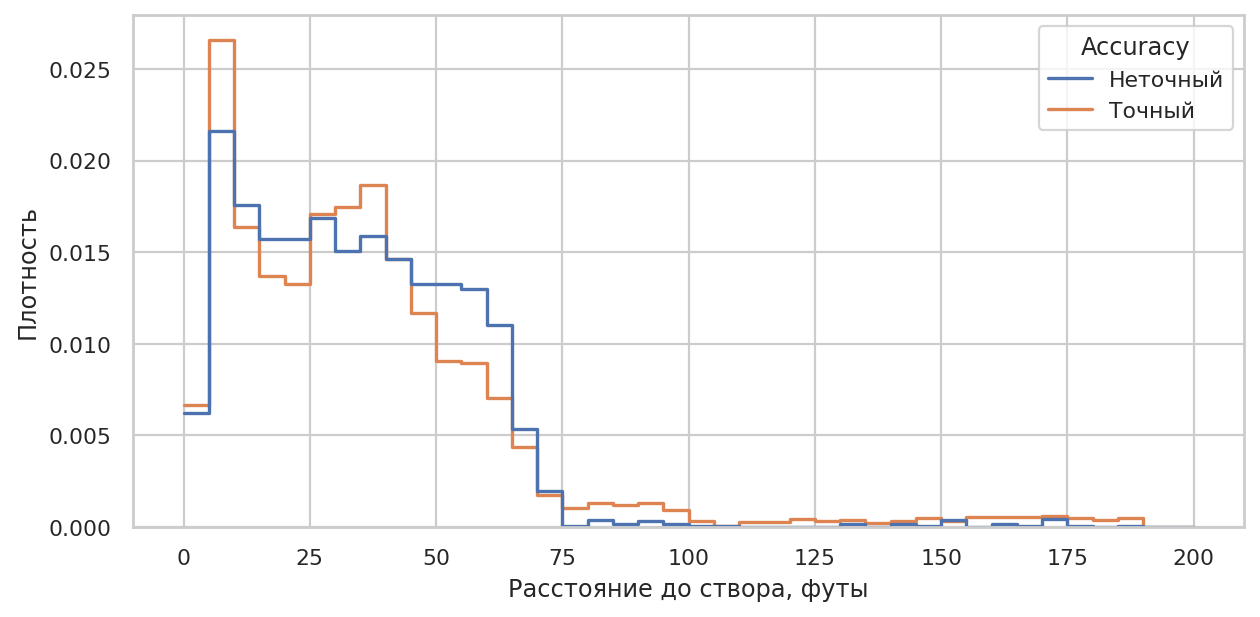

Точные броски со своей половины, по исходу:


,Count
Play Type,
shot-on-goal,168
goal,17


In [9]:
shots["Accuracy"] = np.where(
    shots["Play Type"].eq("missed-shot"), "Неточный", "Точный"
)
shot_summary = shots.groupby("Accuracy")["Shot Length"].agg(
    Count="size", Mean="mean", Median="median"
)
display(shot_summary)
plt.figure(figsize=(8, 4))
sns.histplot(
    data=shots, x="Shot Length", hue="Accuracy",
    bins=np.arange(0, 201, 5), stat="density", common_norm=False,
    element="step", fill=False,
)
plt.xlabel("Расстояние до створа, футы")
plt.ylabel("Плотность")
show_plot("fig9_shot_lengths.png")

own_half = shots["X Coordinate on the Ice Rink"].mul(shots["Goal X"]).lt(0)
print("Точные броски со своей половины, по исходу:")
display(shots[own_half & shots["Accuracy"].eq("Точный")][
    "Play Type"
].value_counts().to_frame("Count"))

Медианы близки: 31.828 фута у точных и 32.249 у неточных бросков.
При этом средняя длина точных больше (36.207 против 34.014) из-за дальнего
хвоста. Поэтому утверждать, что типичный неточный бросок ближе, было бы
неточно: результат зависит от выбора среднего или медианы.
Возможное объяснение хвоста: дальние броски или вбросы, дошедшие до вратаря,
записываются как точные, а часть дальних попыток заканчивается голами
в пустые ворота. Большинство точных бросков со своей половины имеют
тип shot-on-goal, поэтому пустые ворота не объясняют весь хвост.

## 10. Доля точных бросков по каждой команде и игре

Числитель: shot-on-goal + goal. Знаменатель: все незаблокированные броски.
Сначала формируем полный список пар «матч, команда», чтобы нулевые
количества событий не приводили к потере строк.

In [10]:
team_games = pd.concat([
    games.reset_index()[["Game ID", f"{side} Team"]]
    .rename(columns={f"{side} Team": "Team Making the Play"})
    for side in ["Away", "Home"]
]).sort_values(["Game ID", "Team Making the Play"])
team_game_index = pd.MultiIndex.from_frame(team_games)
numshots = (
    events[events["Play Type"].isin(all_shot_types)]
    .groupby(["Game ID", "Team Making the Play", "Play Type"]).size()
    .unstack("Play Type", fill_value=0)
    .reindex(index=team_game_index, columns=all_shot_types, fill_value=0)
)
numshots["On Goal"] = numshots["shot-on-goal"] + numshots["goal"]
numshots["Unblocked"] = numshots["On Goal"] + numshots["missed-shot"]
numshots["Share of Shots on Goal"] = (
    numshots["On Goal"] / numshots["Unblocked"]
)
print("Число пар матч–команда:", len(numshots))
display(pd.concat([numshots.head(), numshots.tail()])[
    ["On Goal", "Unblocked", "Share of Shots on Goal"]
])
display(numshots["Share of Shots on Goal"].describe().to_frame())

Число пар матч–команда: 164


Play Type                        On Goal  Unblocked  Share of Shots on Goal
Game ID    Team Making the Play                                            
2025030111 Boston Bruins              20         32                   0.625
           Buffalo Sabres             38         56                   0.679
2025030112 Boston Bruins              27         44                   0.614
           Buffalo Sabres             35         55                   0.636
2025030113 Boston Bruins              25         36                   0.694
2025030414 Vegas Golden Knights       21         36                   0.583
2025030415 Carolina Hurricanes        24         43                   0.558
           Vegas Golden Knights       25         49                   0.510
2025030416 Carolina Hurricanes        23         36                   0.639
           Vegas Golden Knights       22         37                   0.595

,Share of Shots on Goal
count,164.000
mean,0.639
std,0.085
min,0.353
25%,0.583
50%,0.639
75%,0.689
max,0.860


Средняя доля по 164 наблюдениям равна 0.639, медиана 0.639.
В отдельных матчах она меняется от 0.353 до 0.860.
Доля попаданий в створ заметно колеблется даже при одинаковом
определении броска; она не равна вероятности забить.

## 11. Пять самых высоких и низких средних долей

Усредняем именно доли за матч, без взвешивания числом бросков.

In [11]:
avgnumshots = numshots["Share of Shots on Goal"].groupby(level=1).mean()
print("Самые высокие средние доли:")
display(avgnumshots.nlargest(5).to_frame())
print("Самые низкие средние доли:")
display(avgnumshots.nsmallest(5).to_frame())

Самые высокие средние доли:


,Share of Shots on Goal
Team Making the Play,
Edmonton Oilers,0.706
Philadelphia Flyers,0.684
Dallas Stars,0.670
Minnesota Wild,0.656
Colorado Avalanche,0.653


Самые низкие средние доли:


,Share of Shots on Goal
Team Making the Play,
Pittsburgh Penguins,0.554
Utah Mammoth,0.599
Carolina Hurricanes,0.615
Tampa Bay Lightning,0.626
Buffalo Sabres,0.626


Edmonton лидирует с 0.706, Pittsburgh замыкает список с 0.554:
разница около 15.2 процентного пункта. У Carolina одна из самых низких
долей (0.615), хотя команда дошла до финала. Попадание в створ само по
себе не характеризует результативность или качество опасных моментов.

## 12. Средние броски в створ и голы за матч по 16 командам

Нулевые голы включены в среднее. Голы учитываются в числе бросков в створ.

In [12]:
avgshots = numshots[["On Goal", "goal"]].rename(
    columns={"On Goal": "Shot", "goal": "Goal"}
).groupby(level=1).mean()
display(avgshots)

Play Type,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


## 13. Регрессионная диаграмма

Каждая точка соответствует одной команде. Линия показывает линейную
регрессию, полоса — 95%-й интервал оценки линии по bootstrap seaborn.
Для читаемости подписаны несколько характерных точек.

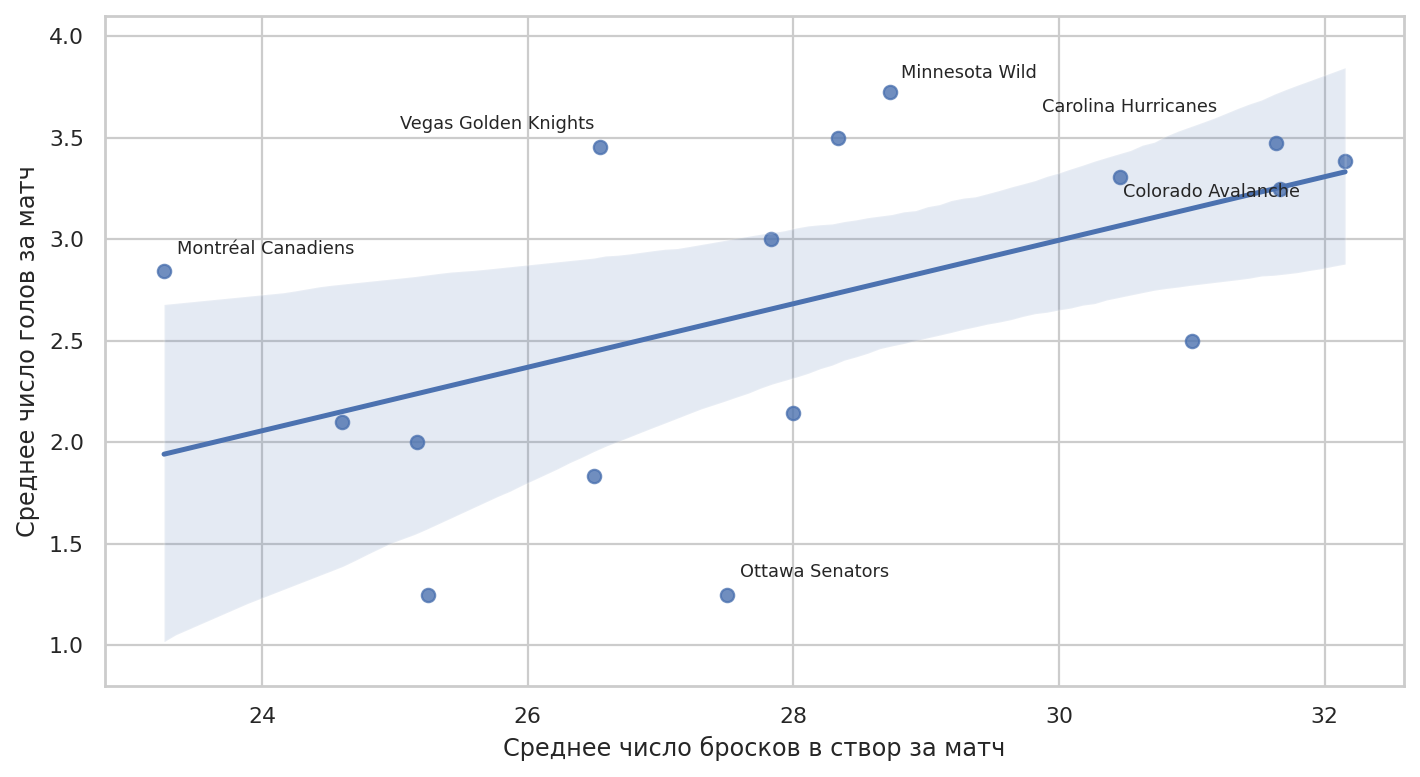

Корреляция Пирсона: 0.521
Наклон регрессии: 0.156, R²: 0.271


In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.regplot(data=avgshots, x="Shot", y="Goal", ax=ax, seed=42)
label_offsets = {
    "Minnesota Wild": (5, 6),
    "Vegas Golden Knights": (-90, 8),
    "Carolina Hurricanes": (-105, 14),
    "Colorado Avalanche": (-100, -16),
    "Montréal Canadiens": (6, 8),
    "Ottawa Senators": (6, 8),
}
for team, offset in label_offsets.items():
    row = avgshots.loc[team]
    ax.annotate(team, (row["Shot"], row["Goal"]), xytext=offset,
                textcoords="offset points", fontsize=8)
ax.set_xlabel("Среднее число бросков в створ за матч")
ax.set_ylabel("Среднее число голов за матч")
ax.set_ylim(0.8, 4.1)
show_plot("fig13_regression.png")
correlation = avgshots["Shot"].corr(avgshots["Goal"])
slope, intercept = np.polyfit(avgshots["Shot"], avgshots["Goal"], 1)
print(f"Корреляция Пирсона: {correlation:.3f}")
print(f"Наклон регрессии: {slope:.3f}, R²: {correlation ** 2:.3f}")

Связь положительная, но точки заметно разбросаны.
Например, Vegas забивает больше Dallas при меньшем числе бросков.
Это описательная связь между средними по 16 командам,
а не доказательство причинности; важны также реализация и качество моментов.

## 14. Матч с наибольшим числом всех бросков

In [14]:
all_shots = events[events["Play Type"].isin(all_shot_types)].copy()
shot_counts = all_shots.groupby("Game ID").size()
max_shot_ids = shot_counts.index[shot_counts.eq(shot_counts.max())]
for game_id in max_shot_ids:
    print(gameInfo(game_id), "— всего бросков:", int(shot_counts.loc[game_id]))
max_shot_game = max_shot_ids[0]
display(all_shots[all_shots["Game ID"].eq(max_shot_game)][
    "Play Type"
].value_counts().to_frame("Count"))

Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20) — всего бросков: 208


,Count
Play Type,
shot-on-goal,83
missed-shot,66
blocked-shot,54
goal,5


Максимум — 208 бросков. Матч продолжался до 13:53 второго овертайма,
то есть 93 минуты 53 секунды; это помогает объяснить большой общий объем.

## 15. Карта бросков этого матча

Для найденного матча хозяева защищают правые ворота в нечетных периодах.
Поэтому отражаем координаты **обеих команд** в нечетных периодах.
После этого хозяева атакуют правые ворота, гости — левые.
Цвет обозначает исход броска, форма точки — команду.
Функция площадки взята из приложенного rink.py.

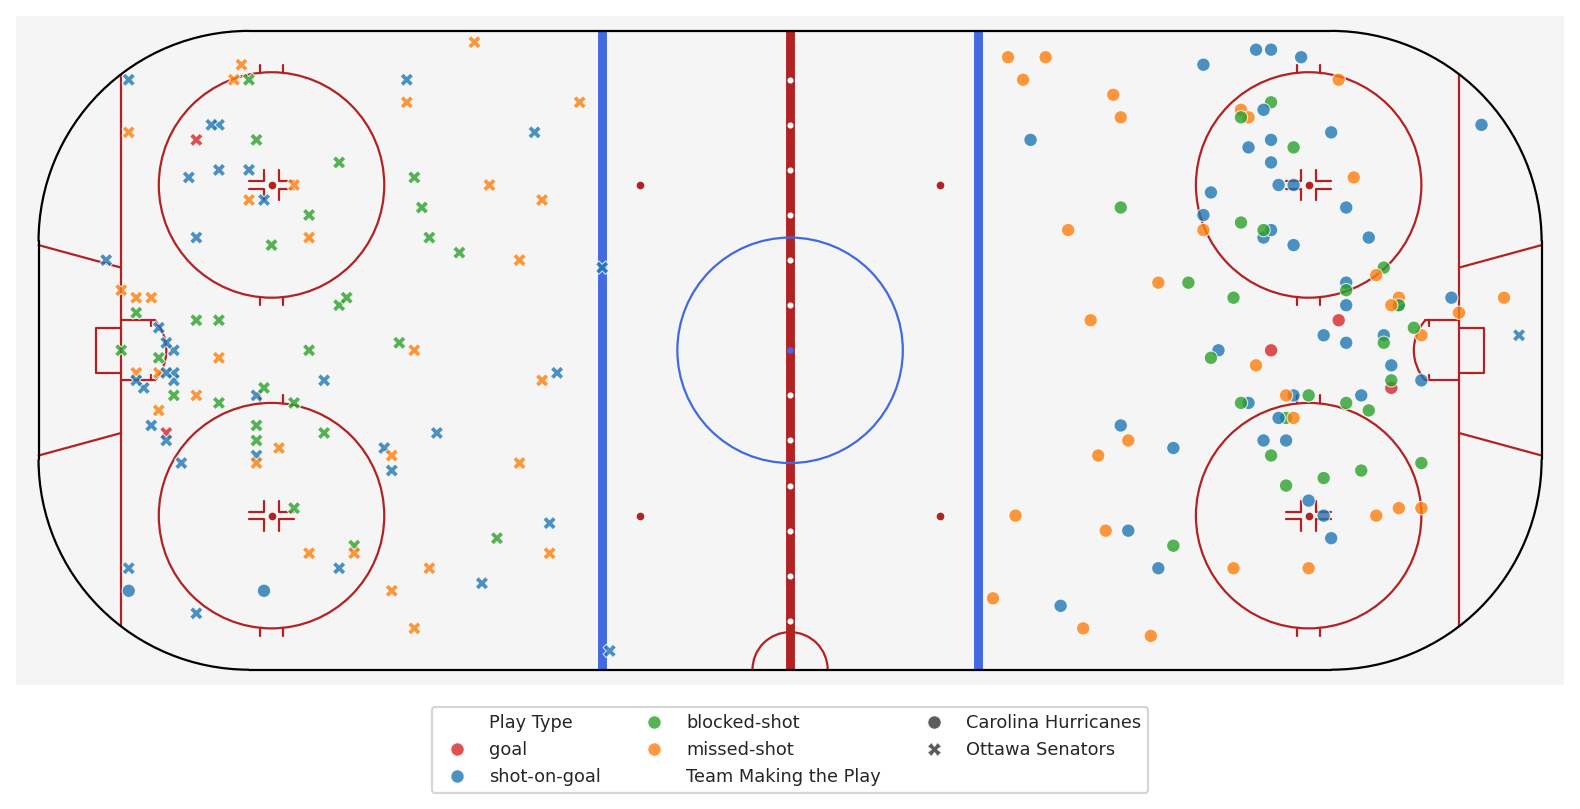

In [15]:
# Функция из приложенного rink.py, встроенная без изменений.
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def plot_rink(annotations=False):
    plt.gcf().gca().add_artist(plt.Rectangle((-103,-44.5), 206, 89,
                                             linewidth=0,
                                             facecolor='whitesmoke',
                                             zorder=-2))
    # Lines dividing the zones
    line, = plt.plot([0,0], [-42.5,42.5], linewidth=4, solid_capstyle='butt', color='firebrick', zorder=-1)
    plt.scatter([0,0,0,0,0,0,0,0,0,0,0,0], [6,12,18,24,30,36,-6,-12,-18,-24,-30,-36], s=3, color='w', zorder=-1)
    for x in [-25, 25]:
        plt.plot([x,x], [-42.5,42.5], linewidth=4, solid_capstyle='butt', color='royalblue', zorder=-1)
    for x in [-25-64, 25+64]:
        plt.plot([x,x], [-36.75,36.75], linewidth=1, solid_capstyle='butt', color='firebrick', zorder=-1)

    # Faceoff circles
    plt.gcf().gca().add_artist(plt.Circle((0,0), 15, fill=False,
                                          linewidth=1, color='royalblue', zorder=-1))
    for x in [69, -69]:
        for y in [22, -22]:
            plt.gcf().gca().add_artist(plt.Circle((x,y), 15, fill=False,
                                                  linewidth=1, color='firebrick', zorder=-1))
            for dx in [-1,1]:
                for dy in [-1,1]:
                    plt.plot([x+dx*3,x+dx*1,x+dx*1], [y+dy*0.5,y+dy*0.5,y+dy*2], linewidth=1, color='firebrick', zorder=-1)
                    plt.plot([x+dx*1.5,x+dx*1.5], [y+dy*14.93,y+dy*16], linewidth=1, color='firebrick', zorder=-1)

    # Faceoff spots
    plt.scatter([0], [0], s=4, color='royalblue', zorder=-1)
    plt.scatter([69,69,-69,-69,-20,-20,20,20], [22,-22,22,-22,22,-22,22,-22], s=6, color='firebrick', zorder=-1)

    # Referee crease
    plt.gcf().gca().add_artist(mpatches.Arc((0,-42.5), 10, 10, angle=0, theta1=0, theta2=180,
                                            color='firebrick', zorder=-1))

    # Goalie creases
    for xscale,thoffset in [(-1,0), (1,180)]:
        plt.plot([xscale*(25+64),xscale*(25+64-4.47)], [-4,-4], linewidth=1, color='firebrick', zorder=-1)
        plt.plot([xscale*(25+64),xscale*(25+64-4.47)], [4,4], linewidth=1, color='firebrick', zorder=-1)
        plt.plot([xscale*(25+64-4),xscale*(25+64-4)], [-4,-3.3], linewidth=1, color='firebrick', zorder=-1)
        plt.plot([xscale*(25+64-4),xscale*(25+64-4)], [4,3.3], linewidth=1, color='firebrick', zorder=-1)
        plt.gcf().gca().add_artist(mpatches.Arc((xscale*(25+64),0), 12, 12,
                                                angle=0, theta1=-41.75+thoffset, theta2=41.75+thoffset,
                                                color='firebrick', zorder=-1))
        plt.plot([xscale*(25+64),xscale*(25+64+10/3),xscale*(25+64+10/3),xscale*(25+64)], [-3,-3,3,3], linewidth=1, color='firebrick', zorder=-1)

    # Goalie trapezoids
    for dx in [-1,1]:
        for dy in [-1,1]:
            plt.plot([dx*(25+64),dx*(100)], [dy*11,dy*14], linewidth=1, color='firebrick', zorder=-1)

    # Outer boundaries
    plt.plot([-100+28,100-28], [42.5,42.5], linewidth=1, color='black', zorder=-1)
    plt.plot([-100+28,100-28], [-42.5,-42.5], linewidth=1, color='black', zorder=-1)
    plt.plot([-100,-100], [-42.5+28,42.5-28], linewidth=1, color='black', zorder=-1)
    plt.plot([100,100], [-42.5+28,42.5-28], linewidth=1, color='black', zorder=-1)
    # Corner arcs
    plt.gcf().gca().add_artist(mpatches.Arc((100-28,42.5-28), 2*28, 2*28, angle=0, theta1=0, theta2=90,
                                            color='black', zorder=-1))
    plt.gcf().gca().add_artist(mpatches.Arc((-100+28,42.5-28), 2*28, 2*28, angle=90, theta1=0, theta2=90,
                                            color='black', zorder=-1))
    plt.gcf().gca().add_artist(mpatches.Arc((-100+28,-42.5+28), 2*28, 2*28, angle=180, theta1=0, theta2=90,
                                            color='black', zorder=-1))
    plt.gcf().gca().add_artist(mpatches.Arc((100-28,-42.5+28), 2*28, 2*28, angle=-90, theta1=0, theta2=90,
                                            color='black', zorder=-1))

    if annotations:
        # Add some annotations
        plt.annotate("$0{,}0$", (2,2), ha='left', va='top')
        plt.annotate("${-}20{,}22$", (-18,24), ha='left', va='top')
        plt.annotate("$69{,}{-}22$", (69,-24), ha='center', va='top')
        plt.annotate("$89{,}0$", (87,0), ha='right', va='center')
        plt.annotate("${-}89{,}0$", (-87,0), ha='left', va='center')

rink_shots = all_shots[all_shots["Game ID"].eq(max_shot_game)].copy()
odd = rink_shots["Period"].mod(2).eq(1)
assert rink_shots.loc[odd, "Home Team's Defending Side"].eq("right").all()
assert rink_shots.loc[~odd, "Home Team's Defending Side"].eq("left").all()
xy_columns = ["X Coordinate on the Ice Rink", "Y Coordinate on the Ice Rink"]
rink_shots.loc[odd, xy_columns] *= -1

fig, ax = plt.subplots(figsize=(10, 5))
plot_rink(False)
sns.scatterplot(
    data=rink_shots, x=xy_columns[0], y=xy_columns[1],
    hue="Play Type", hue_order=["goal", "shot-on-goal", "blocked-shot", "missed-shot"],
    style="Team Making the Play", s=36, alpha=0.8,
    palette={"goal": "#d62728", "shot-on-goal": "#1f77b4",
             "blocked-shot": "#2ca02c", "missed-shot": "#ff7f0e"},
    ax=ax,
)
ax.set_xlim(-103, 103)
ax.set_ylim(-44.5, 44.5)
ax.set_aspect("equal")
ax.axis("off")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3, fontsize=8)
show_plot("fig15_shot_map.png")

## 16. Десять лучших снайперов

Во всех рейтингах при равенстве главного показателя используем
алфавитный порядок имен, чтобы вывести ровно десять игроков.

In [16]:
goals = events[events["Play Type"].eq("goal")].copy()
goal_counts = goals["Player in the Event #1"].value_counts().rename("Goals")
assist_counts = pd.concat([
    goals["Player in the Event #2"], goals["Player in the Event #3"]
]).dropna().value_counts().rename("Assists")
player_stats = pd.concat([goal_counts, assist_counts], axis=1).fillna(0).astype(int)
player_stats.index.name = "Player"
player_stats["Points"] = player_stats["Goals"] + player_stats["Assists"]


def top10(table, metric):
    return table.reset_index().sort_values(
        [metric, "Player"], ascending=[False, True]
    ).head(10).set_index("Player")


display(top10(player_stats[["Goals"]], "Goals"))

,Goals
Player,
Brett Howden,14
Pavel Dorofeyev,12
Logan Stankoven,11
Mitch Marner,10
Jordan Staal,8
Nikolaj Ehlers,8
Alex Newhook,7
Jackson Blake,7
Mark Stone,7


## 17. Десять лучших по голевым передачам

Суммируем оба поля передач только у событий goal, пропуски исключаем.

In [17]:
display(top10(player_stats[["Assists"]], "Assists"))

,Assists
Player,
Jack Eichel,20
Mitch Marner,19
Jackson Blake,13
Lane Hutson,13
Martin Necas,12
Nick Suzuki,12
Shea Theodore,12
Taylor Hall,12
Kirill Kaprizov,11


## 18. Десять лучших по системе «гол плюс пас»

In [18]:
display(top10(player_stats, "Points"))

,Goals,Assists,Points
Player,,,
Mitch Marner,10,19,29
Jack Eichel,2,20,22
Jackson Blake,7,13,20
Taylor Hall,7,12,19
Brett Howden,14,4,18
Nikolaj Ehlers,8,10,18
Shea Theodore,6,12,18
Lane Hutson,3,13,16
Logan Stankoven,11,5,16


## 19. Десять лучших по средним броскам в створ за игру

Знаменатель — число всех матчей, в которых игрок присутствовал в составах.
Игры без бросков также входят в знаменатель. Броски в створ включают голы.
Минимальный порог числа матчей не вводим, поскольку его нет в задании.

In [19]:
games_played = appearances.groupby("Player")["Game ID"].nunique().rename("Games")
on_goal_by_player = (
    events[events["Play Type"].isin(["goal", "shot-on-goal"])]
    ["Player in the Event #1"].value_counts().rename("Shots on Goal")
)
hits_by_player = (
    events[events["Play Type"].eq("hit")]
    ["Player in the Event #1"].value_counts().rename("Hits")
)
player_averages = pd.concat(
    [games_played, on_goal_by_player, hits_by_player], axis=1
).fillna({"Shots on Goal": 0, "Hits": 0})
player_averages.index.name = "Player"
player_averages[["Games", "Shots on Goal", "Hits"]] = (
    player_averages[["Games", "Shots on Goal", "Hits"]].astype(int)
)
player_averages["Shots per Game"] = (
    player_averages["Shots on Goal"] / player_averages["Games"]
)
player_averages["Hits per Game"] = player_averages["Hits"] / player_averages["Games"]
display(top10(player_averages[["Games", "Shots on Goal", "Shots per Game"]],
              "Shots per Game"))

,Games,Shots on Goal,Shots per Game
Player,,,
Jason Robertson,6,30,5.000
Dylan Guenther,6,27,4.500
Nikita Kucherov,7,31,4.429
Matt Boldy,11,48,4.364
Quinton Byfield,4,17,4.250
Darren Raddysh,7,28,4.000
Joel Eriksson Ek,6,24,4.000
Alex Laferriere,4,15,3.750
David Pastrnak,6,22,3.667


## 20. Десять лучших по средним силовым приемам за игру

Аналогично учитываем все сыгранные матчи, в том числе с нулем приемов.
В таблице указано число игр: высокое среднее по одной игре нестабильно.

In [20]:
display(top10(player_averages[["Games", "Hits", "Hits per Game"]], "Hits per Game"))

,Games,Hits,Hits per Game
Player,,,
Lawson Crouse,6,38,6.333
Alex Turcotte,1,6,6.000
Alexander Petrovic,1,6,6.000
Yakov Trenin,9,51,5.667
Dylan Cozens,4,22,5.500
Vasily Podkolzin,6,32,5.333
Carl Grundstrom,3,15,5.000
Ivan Barbashev,22,110,5.000
Marcus Foligno,11,55,5.000


## 21. Вратари, не пропустившие ни одного гола хотя бы в одном матче

Считаем голы соперника при нахождении конкретного вратаря на льду.
Нулевой личный результат подходит и при выходе на замену в матче,
где команда уже пропустила.

В исходных данных у 22 решающих голов в овертаймах отсутствует
**весь состав обеих команд**, а не только вратарь. Для этих записей
используем последнюю известную запись состава того же периода.
Это явное допущение при восстановлении неполных данных.
Если состав заполнен, но вратаря нет, это гол в пустые ворота,
и его не приписываем последнему вратарю.

In [21]:
goalie_records = []
goal_assignments = []
for game_id, game_events in events.groupby("Game ID", sort=True):
    game_events = game_events.sort_values("Play ID")
    for side, opponent in [("Away", "Home"), ("Home", "Away")]:
        goalie_column = f"{side} Team's Goalie"
        slots = [f"{side} Team's Player on the Ice #{i}" for i in range(1, 7)]
        missing_roster = game_events[slots].isna().all(axis=1)
        # Запоминаем индекс последней записи состава, включая настоящие
        # записи без вратаря; простое ffill имени вратаря было бы неверным.
        previous_lineup = game_events.index.to_series().where(~missing_roster)
        previous_lineup = previous_lineup.groupby(game_events["Period"]).ffill()
        effective_goalie = game_events[goalie_column].copy()
        restored = pd.Series(False, index=game_events.index)
        for idx in game_events.index[missing_roster & game_events["Play Type"].eq("goal")]:
            previous_idx = previous_lineup.loc[idx]
            if pd.isna(previous_idx):
                raise ValueError("Нет предшествующего состава для гола.")
            effective_goalie.loc[idx] = game_events.at[previous_idx, goalie_column]
            restored.loc[idx] = True

        against = game_events[
            game_events["Play Type"].eq("goal")
            & game_events["Team Making the Play"].eq(game_events[f"{opponent} Team"])
        ]
        conceded = effective_goalie.loc[against.index].value_counts()
        team = game_events[f"{side} Team"].iloc[0]
        for goalie in game_events[goalie_column].dropna().unique():
            goalie_records.append({
                "Game ID": game_id, "Team": team, "Goalie": goalie,
                "Goals Against": int(conceded.get(goalie, 0)),
            })
        for idx in against.index:
            goal_assignments.append({
                "Event": idx, "Game ID": game_id,
                "Goalie": effective_goalie.loc[idx],
                "Restored": bool(restored.loc[idx]),
            })

goalie_games = pd.DataFrame(goalie_records)
goal_assignments = pd.DataFrame(goal_assignments)
zero_goalie_games = goalie_games[goalie_games["Goals Against"].eq(0)].copy()
goalie_summary = (
    zero_goalie_games.groupby(["Goalie", "Team"]).size()
    .rename("Games Without Goals Against").reset_index()
)
display(goalie_summary)
display(zero_goalie_games.sort_values(["Goalie", "Game ID"]).assign(
    **{"Game Info": lambda x: x["Game ID"].map(gameInfo)}
)[["Goalie", "Game Info", "Goals Against"]])
print(
    f"Всего голов: {len(goal_assignments)}; приписано вратарям: "
    f"{goal_assignments['Goalie'].notna().sum()}; без вратаря: "
    f"{goal_assignments['Goalie'].isna().sum()}; восстановлено составов "
    f"на голах: {goal_assignments['Restored'].sum()}."
)

,Goalie,Team,Games Without Goals Against
0,Andrei Vasilevskiy,Tampa Bay Lightning,1
1,Brandon Bussi,Carolina Hurricanes,1
2,Dan Vladar,Philadelphia Flyers,2
3,Frederik Andersen,Carolina Hurricanes,3
4,Joonas Korpisalo,Boston Bruins,1
5,Scott Wedgewood,Colorado Avalanche,1


,Goalie,Game Info,Goals Against
24,Andrei Vasilevskiy,"Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)",0
172,Brandon Bussi,"Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)",0
38,Dan Vladar,"Pittsburgh Penguins - Philadelphia Flyers (0 - 3, Final, 2026-04-20)",0
47,Dan Vladar,"Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)",0
29,Frederik Andersen,"Carolina Hurricanes - Ottawa Senators (2 - 0, Final, 2026-04-18)",0
111,Frederik Andersen,"Carolina Hurricanes - Philadelphia Flyers (3 - 0, Final, 2026-05-02)",0
149,Frederik Andersen,"Montréal Canadiens - Carolina Hurricanes (0 - 4, Final, 2026-05-27)",0
9,Joonas Korpisalo,"Boston Bruins - Buffalo Sabres (1 - 6, Final, 2026-04-26)",0
129,Scott Wedgewood,"Colorado Avalanche - Minnesota Wild (4 - 3, Final/OT, 2026-05-13)",0


Всего голов: 486; приписано вратарям: 483; без вратаря: 3; восстановлено составов на голах: 22.


Получено 6 разных вратарей и 9 пар «вратарь–матч».
Помимо обычных матчей без пропущенных шайб, в список входят
Joonas Korpisalo (Boston, 26 апреля) и Scott Wedgewood
(Colorado, 13 мая): оба вышли на замену и сами не пропустили.
Такая трактовка учитывает условие о неполном участии.

## 22. Дополнительный вопрос

**Как часто победитель превосходил проигравшего по броскам в створ?**
Сравним суммарные броски в створ команд в каждом матче.

In [22]:
winner_shot_diffs = []
for game_id, game in games.iterrows():
    home_won = game["Home Score"] > game["Away Score"]
    winner = game["Home Team"] if home_won else game["Away Team"]
    loser = game["Away Team"] if home_won else game["Home Team"]
    winner_shot_diffs.append(
        numshots.loc[(game_id, winner), "On Goal"]
        - numshots.loc[(game_id, loser), "On Goal"]
    )
winner_shot_diffs = pd.Series(winner_shot_diffs, index=games.index)
win_comparison = pd.DataFrame({
    "Бросков у победителя": ["Больше", "Столько же", "Меньше"],
    "Число матчей": [
        winner_shot_diffs.gt(0).sum(),
        winner_shot_diffs.eq(0).sum(),
        winner_shot_diffs.lt(0).sum(),
    ],
})
win_comparison["Доля"] = win_comparison["Число матчей"] / len(games)
display(win_comparison)
print(f"Средняя разница: {winner_shot_diffs.mean():.3f} броска.")

,Бросков у победителя,Число матчей,Доля
0,Больше,47,0.573
1,Столько же,4,0.049
2,Меньше,31,0.378


Средняя разница: 1.476 броска.


В 47 из 82 матчей (57.3%) победитель имел больше бросков в створ.
В среднем его преимущество составляет 1.476 броска.
Превосходство по объему бросков встречается чаще у победителя,
но далеко не гарантирует победу; результат зависит также от реализации
и игры вратарей. Вопрос описывает этот плей-офф и не доказывает причинность.